# Experiment 1: differential leakage across groups

The adversary knows the population $\theta$, the target's age, and that the target is in a release of $n = 1000$ records, and wants to infer whether the target has a disability. Knowing $\theta$, the adversary has nothing to learn about it: the gap between the risk $G_g[\pi^{\delta_\theta,1} \triangleright \mathsf{R}]$ and the base-rate risk $\Phi(\theta)$ is entirely differential leakage.

This notebook produces **Figure 1** of the paper:

- **(a)** `figures/figure1a.pdf`: the base-rate risk $\Phi(\theta)$, the risk $G_g[\pi^{\delta_\theta,1} \triangleright \mathsf{R}]$ and its bounds from Theorem 5.1(b), for each age;
- **(b)** `figures/figure1b.pdf`: the age distribution $\theta(\mathit{age})$ and the prevalence of disability by age $\theta(\mathit{disability} \mid \mathit{age})$.

The population $\theta$ is the distribution of the records of the 2010 ACS PUMS over age (`AGEP`, the QID) and disability (`DIS`, the sensitive attribute). The code of the experiment is in `risk_bounds.py`.

In [1]:
import risk_bounds as rb
from build_pums2010 import build_dataset
from common import load_population

data_path = build_dataset()  # downloads and extracts the 2010 ACS PUMS on the first run

Population: 3,061,692 records with no N/A in AGEP, DIS


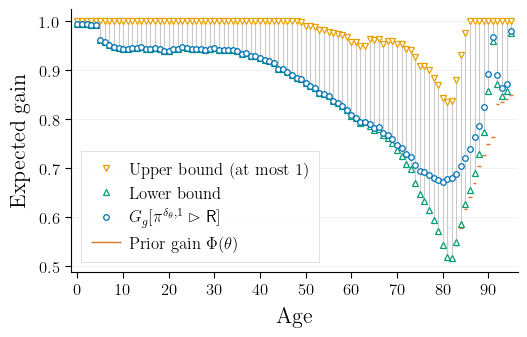

In [2]:
qids, sensitive = ["AGEP"], "DIS"  # QID: age; sensitive attribute: disability
n = 1000  # records in the release

theta = load_population(data_path, qids, sensitive)
table = rb.bounds_table(theta, n)  # a row per age: base-rate risk, risk and its bounds
# Drawn 5.5 in wide for one column of the paper (3.5 in): the text prints at 0.64 of its size
rb.plot(table, "figures/figure1a.pdf", xlabel="Age", figsize=(5.5, 3.6), max_tick_labels=10,
        markersize=4, legend_cols=1)

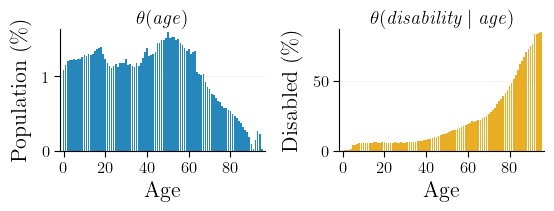

In [3]:
rb.plot_distribution(data_path, "figures/figure1b.pdf")

## Numbers quoted in the text

The text quotes the risk and the base-rate risk at age 91, where the target is often alone or almost alone in the group. The upper bound of Theorem 5.1(b) exceeds 1 there; the figure caps it at 1.

In [4]:
table[table["group"] == "91"]

,group,share,base-rate risk,lower bound,risk,upper bound
91,91,0.000194,0.762226,0.958167,0.968079,2.130246
